# 1일차 EDA — 바이어 연체 현황

- 원본: `data/day1/d1_buyers_raw.xlsx`(읽기만) · 결제조건 코드표: `workbench/day1/outputs/d1_code_table.csv`
- 정리 규칙: `scripts/d1_clean_rules.py` (근거: `workbench/day1/outputs/d1_quality_report.md`)
- **연체 바이어 = `max_dpd_days > 0`**. dpd가 `-` · `확인중`인 바이어는 연체 여부를 알 수 없어 비율의 분모에서 뺀다.
- 기준일 2026-09-30 · 경로는 저장소 맨 위 폴더 기준

In [1]:
# ① 분석용 표 만들기 — 원본은 읽기만 하고 메모리에서 정리한다(규칙: scripts/d1_clean_rules.py)
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib import font_manager

from scripts.d1_clean_rules import build_analysis_table, to_markdown_table

FONT = "tools/fonts/NanumGothic-Regular.ttf"
font_manager.fontManager.addfont(FONT)
# 한글은 나눔고딕, 나눔고딕에 없는 글자(예: Türkiye의 ü)는 DejaVu Sans로 대체
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=FONT).get_name(), "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
CHARTS = Path("workbench/day1/outputs/charts")

df, log = build_analysis_table()
for k, v in log.items():
    print(f"{k}: {v}")

base = df[~df["dpd_확인필요"]].copy()  # 연체 여부를 판단할 수 있는 바이어
base["is_overdue"] = base["is_overdue"].astype(bool)
print(f"연체 판단 가능 바이어: {len(base)} / 연체 바이어(dpd>0): {int(base.is_overdue.sum())} "
      f"({base.is_overdue.mean():.1%})")
flags = ["ar_balance_근사치", "overdue_amount_근사치", "통화_확인필요", "날짜_모호", "oecd_crc_해당없음"]
print("플래그 수:", {c: int(df[c].sum()) for c in flags})
df[["buyer_id", "country", "pay_method", "max_dpd_days", "is_overdue", "ar_balance", "ar_currency", "since_date"]].head()

원본 행: 153
완전 중복 삭제: 1
buyer_id 중복(첫 행 유지) 삭제: 2
분석 행: 150
dpd 확인필요(빈칸 처리): 2
결제방식 코드표에 없음: 0
결제방식 검토 필요: 1
연체 판단 가능 바이어: 148 / 연체 바이어(dpd>0): 25 (16.9%)
플래그 수: {'ar_balance_근사치': 3, 'overdue_amount_근사치': 3, '통화_확인필요': 2, '날짜_모호': 14, 'oecd_crc_해당없음': 57}


,buyer_id,country,pay_method,max_dpd_days,is_overdue,ar_balance,ar_currency,since_date
0,B001,Netherlands,OA,0.0,False,23730.0,EUR,2013-12-09
1,B002,China,OA,0.0,False,10070.0,USD,2020-09-14
2,B003,Indonesia,DA,0.0,False,0.0,USD,2018-06-27
3,B004,Egypt,LC_SIGHT,0.0,False,0.0,USD,2024-06-20
4,B005,Vietnam,OA,13.0,True,346360.0,USD,2023-07-21


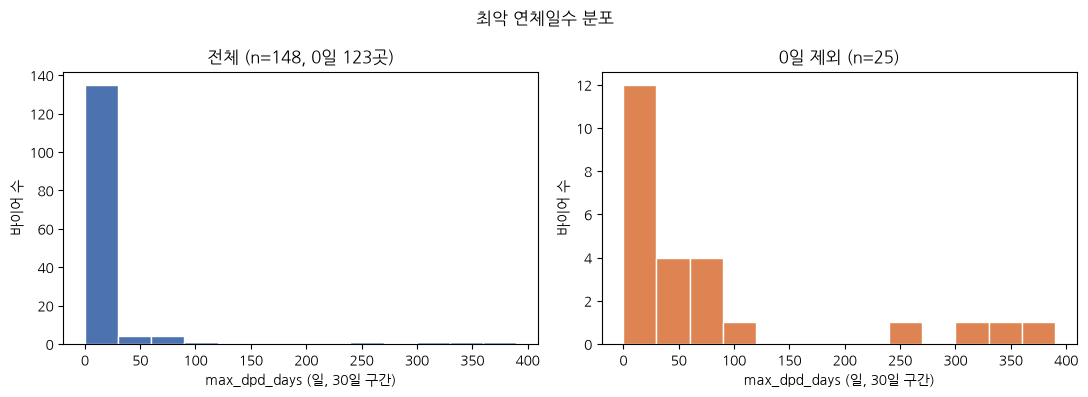

0일 제외 요약: {'count': 25.0, 'mean': 81.0, 'std': 114.0, 'min': 3.0, '25%': 15.0, '50%': 31.0, '75%': 74.0, 'max': 381.0}
연체 구간별 바이어 수: {'1-30': 12, '31-60': 4, '61-90': 5, '91+': 4}
91일 이상: [['B044', 'Thailand', 355.0], ['B071', 'Taiwan', 269.0], ['B083', 'United States', 305.0], ['B147', 'Thailand', 381.0]]
그림에서 뺀 dpd 확인필요: [['B058', '-'], ['B066', '확인중']]


In [2]:
# ② 차트 1 — max_dpd_days 분포(전체 / 0일 제외), 30일 구간
d = base["max_dpd_days"]
pos = d[d > 0]
bins = range(0, int(d.max()) + 31, 30)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(d, bins=bins, color="#4C72B0", edgecolor="white")
axes[0].set_title(f"전체 (n={len(d)}, 0일 {int((d == 0).sum())}곳)")
axes[1].hist(pos, bins=bins, color="#DD8452", edgecolor="white")
axes[1].set_title(f"0일 제외 (n={len(pos)})")
for ax in axes:
    ax.set_xlabel("max_dpd_days (일, 30일 구간)")
    ax.set_ylabel("바이어 수")
fig.suptitle("최악 연체일수 분포")
fig.tight_layout()
fig.savefig(CHARTS / "dpd_hist.png", dpi=150)
plt.show()

print("0일 제외 요약:", pos.describe().round(1).to_dict())
bucket = pd.cut(pos, [0, 30, 60, 90, 10_000], labels=["1-30", "31-60", "61-90", "91+"])
print("연체 구간별 바이어 수:", bucket.value_counts().sort_index().to_dict())
print("91일 이상:", base.loc[base.max_dpd_days >= 91, ["buyer_id", "country", "max_dpd_days"]].values.tolist())
print("그림에서 뺀 dpd 확인필요:", df.loc[df["dpd_확인필요"], ["buyer_id", "max_dpd_days_raw"]].values.tolist())

**차트 1 해석** (`charts/dpd_hist.png`)

1. 연체 여부를 판단할 수 있는 148곳 중 123곳(83.1%)은 연체 0일이고, 연체 바이어(dpd > 0)는 25곳(16.9%)이다.
2. 연체 25곳 중 12곳은 1~30일의 짧은 지연이지만 꼬리가 길어 평균 81.0일이 중앙값 31.0일보다 훨씬 크다(구간별 1-30: 12 · 31-60: 4 · 61-90: 5 · 91+: 4).
3. 91일 이상 4곳(B147 Thailand 381 · B044 Thailand 355 · B083 United States 305 · B071 Taiwan 269)은 사전상 채무불이행 추정 구간이라 우선 확인 대상이다. dpd가 `-` · `확인중`인 2곳(B058 · B066)은 그림에서 빠졌으므로 '확인 필요'.

10위 비율과 같아 잘린 국가: []


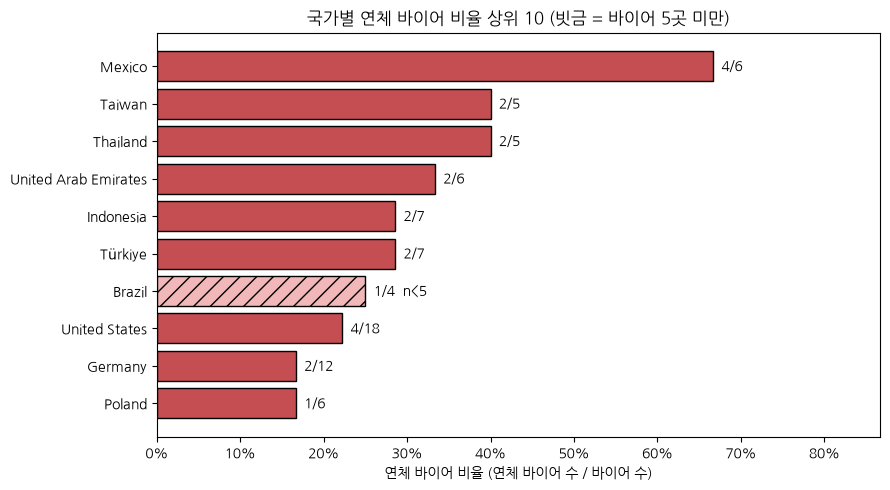

| country | 바이어수 | 연체바이어수 | 연체비율 |
|---|---|---|---|
| Mexico | 6 | 4 | 66.7% |
| Taiwan | 5 | 2 | 40.0% |
| Thailand | 5 | 2 | 40.0% |
| United Arab Emirates | 6 | 2 | 33.3% |
| Indonesia | 7 | 2 | 28.6% |
| Türkiye | 7 | 2 | 28.6% |
| Brazil | 4 | 1 | 25.0% |
| United States | 18 | 4 | 22.2% |
| Germany | 12 | 2 | 16.7% |
| Poland | 6 | 1 | 16.7% |
| India | 10 | 1 | 10.0% |
| Vietnam | 12 | 1 | 8.3% |
| China | 14 | 1 | 7.1% |
| Japan | 10 | 0 | 0.0% |
| United Kingdom | 6 | 0 | 0.0% |
| Netherlands | 5 | 0 | 0.0% |
| Saudi Arabia | 5 | 0 | 0.0% |
| Egypt | 4 | 0 | 0.0% |
| Malaysia | 3 | 0 | 0.0% |
| Nigeria | 3 | 0 | 0.0% |


In [3]:
# ③ 차트 2 — 국가별 연체 바이어 비율 상위 10 (바이어 5곳 미만 국가는 빗금 + n<5 표시)
g = base.groupby("country").agg(바이어수=("buyer_id", "size"), 연체바이어수=("is_overdue", "sum"))
g["연체비율"] = g["연체바이어수"] / g["바이어수"]
g = g.sort_values(["연체비율", "바이어수"], ascending=[False, False])
top = g.head(10)
cut = top["연체비율"].iloc[-1]
print("10위 비율과 같아 잘린 국가:", g.iloc[10:][g.iloc[10:]["연체비율"] == cut].index.tolist())

fig, ax = plt.subplots(figsize=(9, 5))
small = top["바이어수"] < 5
bars = ax.barh(top.index[::-1], top["연체비율"][::-1], color="#C44E52", edgecolor="black",
               hatch=None)
for bar, is_small in zip(bars, small[::-1]):
    if is_small:
        bar.set_hatch("//")
        bar.set_facecolor("#F2B8B9")
for y, (name, r) in enumerate(top[::-1].iterrows()):
    note = "  n<5" if r["바이어수"] < 5 else ""
    ax.text(r["연체비율"] + 0.01, y, f"{int(r['연체바이어수'])}/{int(r['바이어수'])}{note}", va="center")
ax.set_xlim(0, min(1.0, top["연체비율"].max() + 0.2))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("연체 바이어 비율 (연체 바이어 수 / 바이어 수)")
ax.set_title("국가별 연체 바이어 비율 상위 10 (빗금 = 바이어 5곳 미만)")
fig.tight_layout()
fig.savefig(CHARTS / "country_overdue_top10.png", dpi=150)
plt.show()

print(to_markdown_table(g.reset_index().assign(연체비율=lambda t: t["연체비율"].map("{:.1%}".format))))

**차트 2 해석** (`charts/country_overdue_top10.png`)

1. Mexico가 6곳 중 4곳(66.7%)으로 가장 높고, Taiwan · Thailand 40.0%(각 2/5), United Arab Emirates 33.3%(2/6)가 뒤따른다.
2. 국가별 바이어가 3~18곳뿐이라 1곳 차이로 비율이 크게 움직인다(Brazil 1/4 = 25.0%는 5곳 미만). 비율은 22.2%지만 연체 바이어 수는 4곳으로 Mexico와 같은 United States처럼, 비율과 건수를 함께 봐야 한다.
3. 같은 40%라도 Thailand는 연체 2곳이 모두 91일 이상(B044 355일 · B147 381일)이고, Taiwan은 2곳 중 1곳이 269일(B071)이다. 따라서 국가 비교는 연체 비율만이 아니라 연체 깊이(dpd)와 함께 해야 한다.

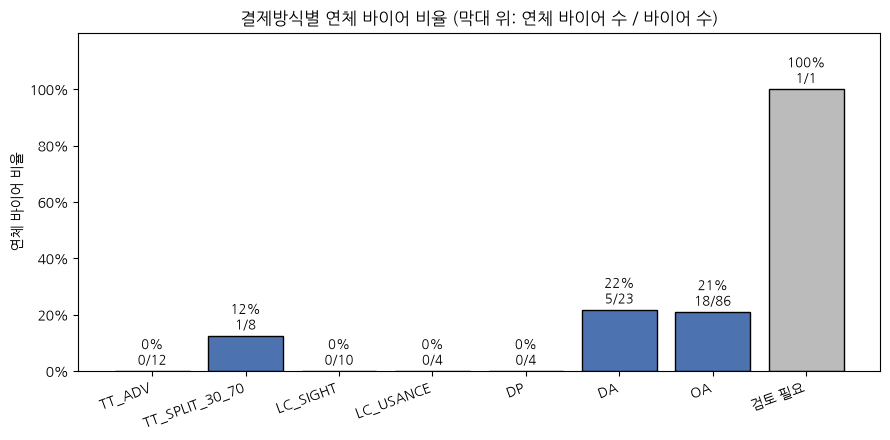

| 결제방식 | 바이어 수 | 연체 바이어 수 | 연체 바이어 비율 |
|---|---|---|---|
| TT_ADV | 12 | 0 | 0.0% |
| TT_SPLIT_30_70 | 8 | 1 | 12.5% |
| LC_SIGHT | 10 | 0 | 0.0% |
| LC_USANCE | 4 | 0 | 0.0% |
| DP | 4 | 0 | 0.0% |
| DA | 23 | 5 | 21.7% |
| OA | 86 | 18 | 20.9% |
| 검토 필요 | 1 | 1 | 100.0% |
| 합계 | 148 | 25 | 16.9% |
검토 필요 · TT_SPLIT 연체 바이어: [['B085', 'United Arab Emirates', '10% T/T advance + 90% O/A 90 days', 22.0], ['B087', 'Taiwan', '30% T/T advance, 70% within 30 days after B/L', 32.0]]


In [4]:
# ④ 차트 3 — 결제방식(표준 코드)별 연체 바이어 비율 + 표
ORDER = ["TT_ADV", "TT_SPLIT_30_70", "LC_SIGHT", "LC_USANCE", "DP", "DA", "OA", "검토 필요"]
p = base.groupby("pay_method").agg(바이어수=("buyer_id", "size"), 연체바이어수=("is_overdue", "sum"))
p = p.reindex([c for c in ORDER if c in p.index])
p["연체비율"] = p["연체바이어수"] / p["바이어수"]

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#BBBBBB" if c == "검토 필요" else "#4C72B0" for c in p.index]
ax.bar(p.index, p["연체비율"], color=colors, edgecolor="black")
for x, (code, r) in enumerate(p.iterrows()):
    ax.text(x, r["연체비율"] + 0.01, f"{r['연체비율']:.0%}\n{int(r['연체바이어수'])}/{int(r['바이어수'])}",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, p["연체비율"].max() + 0.2)  # 막대 위 글자 자리
ax.set_yticks([i / 5 for i in range(6)])  # 눈금은 100%까지
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylabel("연체 바이어 비율")
ax.set_title("결제방식별 연체 바이어 비율 (막대 위: 연체 바이어 수 / 바이어 수)")
plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
fig.tight_layout()
fig.savefig(CHARTS / "paymethod_overdue.png", dpi=150)
plt.show()

table = p.reset_index().rename(columns={"pay_method": "결제방식", "바이어수": "바이어 수",
                                        "연체바이어수": "연체 바이어 수", "연체비율": "연체 바이어 비율"})
table["연체 바이어 비율"] = table["연체 바이어 비율"].map("{:.1%}".format)
total = pd.DataFrame([{"결제방식": "합계", "바이어 수": int(p["바이어수"].sum()),
                       "연체 바이어 수": int(p["연체바이어수"].sum()),
                       "연체 바이어 비율": f"{p['연체바이어수'].sum() / p['바이어수'].sum():.1%}"}])
print(to_markdown_table(pd.concat([table, total], ignore_index=True)))
print("검토 필요 · TT_SPLIT 연체 바이어:", base.loc[base.pay_method.isin(["검토 필요", "TT_SPLIT_30_70"]) & base.is_overdue, ["buyer_id", "country", "payment_terms_raw", "max_dpd_days"]].values.tolist())

**차트 3 해석** (`charts/paymethod_overdue.png`)

1. 외상 조건인 DA(21.7%, 5/23)와 OA(20.9%, 18/86)에서 연체 바이어 25곳 중 23곳이 나왔다. OA는 바이어 수도 86곳으로 가장 많아 연체 관리의 중심이다.
2. TT_ADV(0/12) · LC_SIGHT(0/10) · LC_USANCE(0/4) · DP(0/4)는 연체가 0곳이다. 다만 각 4~12곳으로 적어 "이 방식은 연체가 없다"고 일반화하기는 어렵다.
3. TT_SPLIT_30_70의 연체 1곳은 B087(Taiwan, 32일)이다. `검토 필요` 1곳(B085 United Arab Emirates, `10% T/T advance + 90% O/A 90 days`, 22일)은 1/1이라 비율 100%에 의미가 없고, 코드가 정해지면 다시 계산해야 한다.